# Ollama model benchmark

Compare five Ollama catalog models on the same small, repeatable prompt set. The benchmark reports request latency, prompt/completion tokens, generation throughput, failures and representative responses; it does not claim that a faster or longer answer is more correct.

| Model tag | Catalog | License shown by source |
|---|---|---|
| `nemotron-3-nano:30b` | [Ollama](https://ollama.com/library/nemotron-3-nano) | NVIDIA Open Model License Agreement (open model/weights; not an OSI-approved license) |
| `qwen2.5:7b` | [Ollama](https://ollama.com/library/qwen2.5) | Apache 2.0 |
| `mistral:7b` | [Ollama](https://ollama.com/library/mistral) | Apache 2.0 |
| `granite3.3:8b` | [Ollama](https://ollama.com/library/granite3.3) | Apache 2.0 |
| `deepseek-r1:8b` | [Ollama](https://ollama.com/library/deepseek-r1) | MIT |

**Before you run:** these models must already be pulled to the Ollama server. Nemotron 30B is particularly large and can require substantial RAM/VRAM; this notebook will not download models automatically. Run `ollama pull <model-tag>` for the models you want to test. By default execution is disabled until you explicitly set `RUN_BENCHMARK = True` below. Use the same hardware, Ollama version, options and prompt set when comparing results. This benchmark uses a neutral shared system prompt, no tools, and temperature 0; model capabilities and prompt formatting still differ.

In [14]:
import os
import time
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from ollama import Client

MODELS = [
    "nemotron-3-nano:30b",
    "qwen2.5:7b",
    "mistral:7b",
    "granite3.3:8b",
    "deepseek-r1:8b",
]
PROMPTS = [
    {
        "task": "Arithmetic",
        "prompt": "What is 17 multiplied by 24? Give the result and a one-line calculation.",
    },
    {
        "task": "Instruction following",
        "prompt": "Explain what an API is in exactly 3 numbered bullet points. Keep every bullet under 12 words.",
    },
    {
        "task": "Reasoning",
        "prompt": "A train leaves at 10:15 and travels for 2 hours 35 minutes. What time does it arrive? Show one short calculation.",
    },
    {
        "task": "Code generation",
        "prompt": "Write a Python function named is_palindrome(text) that ignores spaces and letter case. Return only code.",
    },
    {
        "task": "Summarization",
        "prompt": "Summarize in one sentence: A community garden started with twelve volunteers. After a year, weekly workshops had doubled attendance, and the group donated its first harvest to a nearby food bank.",
    },
]
SYSTEM_PROMPT = "You are a helpful assistant. Follow the user's instructions directly and accurately."
OLLAMA_HOST = os.getenv("OLLAMA_HOST", "http://localhost:11434")
TEMPERATURE = 0
REPEATS = 1  # Increase for more stable per-model statistics; total calls = 5 models x 5 prompts x REPEATS.
REQUEST_TIMEOUT_SECONDS = 600

client = Client(host=OLLAMA_HOST, timeout=REQUEST_TIMEOUT_SECONDS)
print(f"Ollama host: {OLLAMA_HOST}")
print("Models:", ", ".join(MODELS))

Ollama host: http://localhost:11434
Models: nemotron-3-nano:30b, qwen2.5:7b, mistral:7b, granite3.3:8b, deepseek-r1:8b


In [12]:
local_models = client.list().models
installed = {model.model for model in local_models}
missing = [model for model in MODELS if model not in installed]
if missing:
    raise RuntimeError(
        "Pull these models on the configured Ollama server before benchmarking: "
        + ", ".join(f"ollama pull {model}" for model in missing)
    )

records = []
total_runs = len(MODELS) * len(PROMPTS) * REPEATS
started_at = datetime.now(timezone.utc).isoformat()
run_number = 0

for model_name in MODELS:
    print(f"Benchmarking {model_name}")
    for repetition in range(1, REPEATS + 1):
        for case in PROMPTS:
            run_number += 1
            print(f"  [{run_number}/{total_runs}] repeat {repetition}: {case['task']}", flush=True)
            started = time.perf_counter()
            try:
                response = client.chat(
                    model=model_name,
                    messages=[
                        {"role": "system", "content": SYSTEM_PROMPT},
                        {"role": "user", "content": case["prompt"]},
                    ],
                    options={"temperature": TEMPERATURE},
                    stream=False,
                )
                elapsed = time.perf_counter() - started
                message = response.message
                eval_duration = getattr(response, "eval_duration", None)
                completion_tokens = getattr(response, "eval_count", None)
                records.append({
                    "model": model_name,
                    "repetition": repetition,
                    "task": case["task"],
                    "prompt": case["prompt"],
                    "response": message.content,
                    "latency_seconds": elapsed,
                    "prompt_tokens": getattr(response, "prompt_eval_count", None),
                    "completion_tokens": completion_tokens,
                    "tokens_per_second": (
                        completion_tokens / (eval_duration / 1e9)
                        if completion_tokens is not None and eval_duration
                        else None
                    ),
                    "success": True,
                    "error": None,
                })
            except Exception as error:
                elapsed = time.perf_counter() - started
                records.append({
                    "model": model_name,
                    "repetition": repetition,
                    "task": case["task"],
                    "prompt": case["prompt"],
                    "response": None,
                    "latency_seconds": elapsed,
                    "prompt_tokens": None,
                    "completion_tokens": None,
                    "tokens_per_second": None,
                    "success": False,
                    "error": f"{type(error).__name__}: {error}",
                })

results = pd.DataFrame(records)
results["benchmark_started_at_utc"] = started_at
display(results[["model", "repetition", "task", "latency_seconds", "prompt_tokens", "completion_tokens",
                 "tokens_per_second", "success", "error"]])

Benchmarking nemotron-3-nano:30b
  [1/25] repeat 1: Arithmetic
  [2/25] repeat 1: Instruction following
  [3/25] repeat 1: Reasoning
  [4/25] repeat 1: Code generation
  [5/25] repeat 1: Summarization
Benchmarking qwen2.5:7b
  [6/25] repeat 1: Arithmetic
  [7/25] repeat 1: Instruction following
  [8/25] repeat 1: Reasoning
  [9/25] repeat 1: Code generation
  [10/25] repeat 1: Summarization
Benchmarking mistral:7b
  [11/25] repeat 1: Arithmetic
  [12/25] repeat 1: Instruction following
  [13/25] repeat 1: Reasoning
  [14/25] repeat 1: Code generation
  [15/25] repeat 1: Summarization
Benchmarking granite3.3:8b
  [16/25] repeat 1: Arithmetic
  [17/25] repeat 1: Instruction following
  [18/25] repeat 1: Reasoning
  [19/25] repeat 1: Code generation
  [20/25] repeat 1: Summarization
Benchmarking deepseek-r1:8b
  [21/25] repeat 1: Arithmetic
  [22/25] repeat 1: Instruction following
  [23/25] repeat 1: Reasoning
  [24/25] repeat 1: Code generation
  [25/25] repeat 1: Summarization


,model,repetition,task,latency_seconds,prompt_tokens,completion_tokens,tokens_per_second,success,error
0,nemotron-3-nano:30b,1,Arithmetic,48.015340,51.0,71.0,5.566354,True,NaN
1,nemotron-3-nano:30b,1,Instruction following,52.224635,54.0,262.0,6.040528,True,NaN
2,nemotron-3-nano:30b,1,Reasoning,39.404241,63.0,204.0,6.726666,True,NaN
3,nemotron-3-nano:30b,1,Code generation,33.025209,53.0,135.0,5.532536,True,NaN
4,nemotron-3-nano:30b,1,Summarization,16.953803,69.0,46.0,5.940670,True,NaN
5,qwen2.5:7b,1,Arithmetic,10.376228,48.0,36.0,49.017138,True,NaN
6,qwen2.5:7b,1,Instruction following,0.563678,51.0,25.0,51.271113,True,NaN
7,qwen2.5:7b,1,Reasoning,1.561735,60.0,75.0,49.508382,True,NaN
8,qwen2.5:7b,1,Code generation,0.819378,49.0,39.0,50.368595,True,NaN
9,qwen2.5:7b,1,Summarization,0.746574,66.0,35.0,50.256163,True,NaN


Benchmark not run. Review the model availability and settings above, then set RUN_BENCHMARK = True and rerun this cell.


,runs,successful_runs,mean_latency_seconds,median_latency_seconds,p95_latency_seconds,prompt_tokens,completion_tokens,mean_completion_tokens,mean_tokens_per_second,error_rate_percent
model,,,,,,,,,,
nemotron-3-nano:30b,5,5,37.92,39.40,51.38,290.0,718.0,143.6,5.96,0.0
qwen2.5:7b,5,5,2.81,0.82,8.61,274.0,210.0,42.0,50.08,0.0
mistral:7b,5,5,5.82,3.02,17.40,253.0,442.0,88.4,51.88,0.0
granite3.3:8b,5,5,2.76,2.69,5.10,295.0,385.0,77.0,44.87,0.0
deepseek-r1:8b,5,3,251.44,32.16,600.11,129.0,2114.0,704.7,43.29,40.0


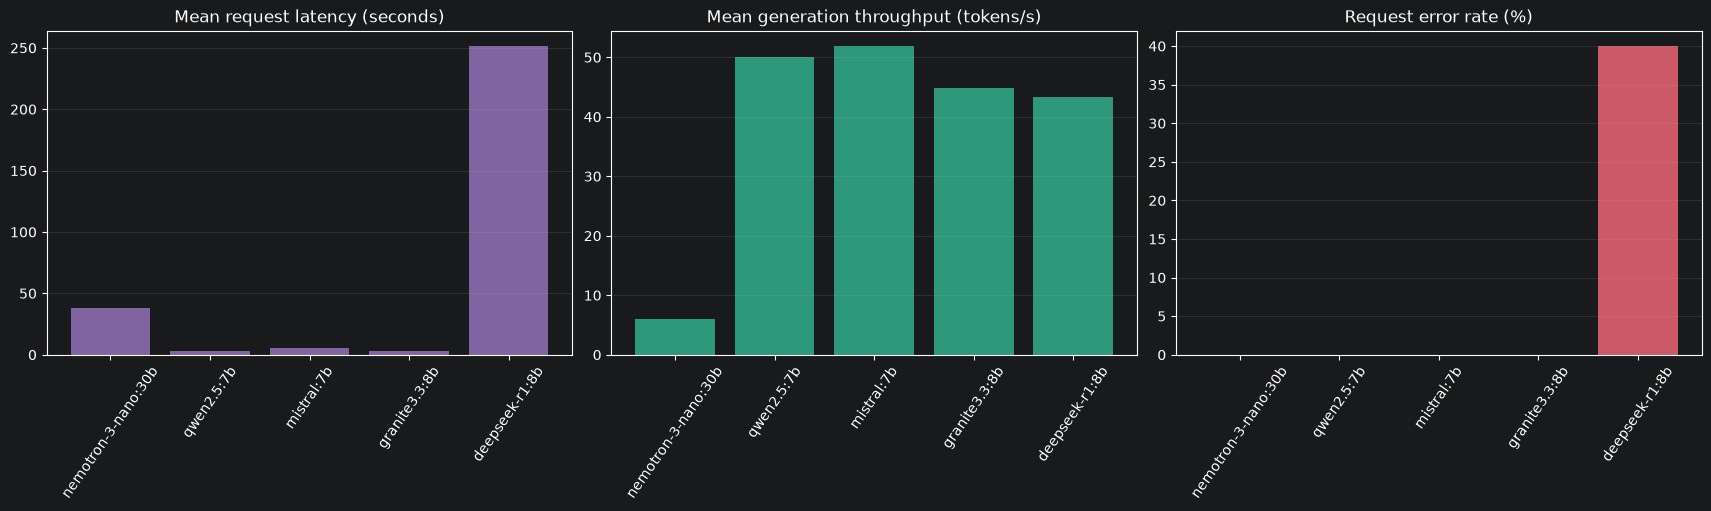

Per-task responses for qualitative inspection:


,model,repetition,task,response,error
0,nemotron-3-nano:30b,1,Arithmetic,\(17 \times 24 = 408\),NaN
1,nemotron-3-nano:30b,1,Instruction following,1. Interface that lets programs talk to each o...,NaN
2,nemotron-3-nano:30b,1,Reasoning,**Calculation:** \n\(10{:}15 + 2\text{ h }35\...,NaN
3,nemotron-3-nano:30b,1,Code generation,```python\ndef is_palindrome(text):\n clean...,NaN
4,nemotron-3-nano:30b,1,Summarization,A community garden that began with twelve volu...,NaN
5,qwen2.5:7b,1,Arithmetic,The result of 17 multiplied by 24 is 408. Calc...,NaN
6,qwen2.5:7b,1,Instruction following,- API stands for Application Programming Inter...,NaN
7,qwen2.5:7b,1,Reasoning,"To find the arrival time, add 2 hours 35 minut...",NaN
8,qwen2.5:7b,1,Code generation,```python\ndef is_palindrome(text):\n clean...,NaN
9,qwen2.5:7b,1,Summarization,A community garden initiated by twelve volunte...,NaN


Some requests failed; see their explicit error values above. These failures are included in each model's error rate.
Latency includes model load time on the first request after a model is unloaded. Repeat a run to compare warm latency, or report first-run and repeated-run measurements separately.
With REPEATS=1 there are only five cases per model, so percentiles are descriptive rather than robust estimates.
Detailed results saved to model_benchmark_results.csv; summary saved to model_benchmark_summary.csv.


In [16]:
if not results.empty:
    successful = results[results["success"]].copy()
    summary = results.groupby("model", sort=False).agg(
        runs=("task", "size"),
        successful_runs=("success", "sum"),
        mean_latency_seconds=("latency_seconds", "mean"),
        median_latency_seconds=("latency_seconds", "median"),
        p95_latency_seconds=("latency_seconds", lambda values: values.quantile(0.95)),
        prompt_tokens=("prompt_tokens", "sum"),
        completion_tokens=("completion_tokens", "sum"),
        mean_completion_tokens=("completion_tokens", "mean"),
        mean_tokens_per_second=("tokens_per_second", "mean"),
    )
    summary["error_rate_percent"] = (1 - summary["successful_runs"] / summary["runs"]) * 100
    summary["mean_latency_seconds"] = summary["mean_latency_seconds"].round(2)
    summary["median_latency_seconds"] = summary["median_latency_seconds"].round(2)
    summary["p95_latency_seconds"] = summary["p95_latency_seconds"].round(2)
    summary["mean_completion_tokens"] = summary["mean_completion_tokens"].round(1)
    summary["mean_tokens_per_second"] = summary["mean_tokens_per_second"].round(2)
    display(summary)

    if not successful.empty:
        figure, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
        plot_data = summary.reset_index()
        axes[0].bar(plot_data["model"], plot_data["mean_latency_seconds"], color="#8064a2")
        axes[0].set_title("Mean request latency (seconds)")
        axes[1].bar(plot_data["model"], plot_data["mean_tokens_per_second"], color="#2d987a")
        axes[1].set_title("Mean generation throughput (tokens/s)")
        axes[2].bar(plot_data["model"], plot_data["error_rate_percent"], color="#cc5967")
        axes[2].set_title("Request error rate (%)")
        for axis in axes:
            axis.tick_params(axis="x", labelrotation=55)
            axis.grid(axis="y", alpha=0.2)
        plt.show()

    print("Per-task responses for qualitative inspection:")
    display(results[["model", "repetition", "task", "response", "error"]])
    if not results["success"].all():
        print(
            "Some requests failed; see their explicit error values above. These failures are included in each model's error rate.")
    print(
        "Latency includes model load time on the first request after a model is unloaded. Repeat a run to compare warm latency, or report first-run and repeated-run measurements separately.")
    print(
        "With REPEATS=1 there are only five cases per model, so percentiles are descriptive rather than robust estimates.")
    output_path = "model_benchmark_results.csv"
    results.to_csv(output_path, index=False)
    summary.to_csv("model_benchmark_summary.csv")
    print(f"Detailed results saved to {output_path}; summary saved to model_benchmark_summary.csv.")